In [1]:
def cleanup_gpu():
    import gc
    import torch

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

cleanup_gpu()

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
import os

# Xác định thư mục gốc của dự án (lùi ra 1 cấp so với thư mục notebooks)
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

# Thêm thư mục gốc vào sys.path để Python có thể tìm thấy bus_benchmark
if project_root not in sys.path:
    sys.path.append(project_root)

In [4]:
import os
os.environ["ROOT_PATH"] = os.getcwd()

In [5]:
# !pip install python-dotenv

In [6]:
# !pip install wandb

## Load dataset and select the most common route

In [7]:
import pandas as pd

data_set = "Rotterdam"
lau_id = "GM0599"

df_parquet = pd.read_parquet(f"../data/parquet_data/{lau_id}.parquet")
df_parquet['from_time'] = df_parquet['from_time'].dt.tz_convert('Europe/Amsterdam')
df_parquet['to_time'] = df_parquet['to_time'].dt.tz_convert('Europe/Amsterdam')
df_parquet

,lau,date,line,trip,from_stop,to_stop,from_geometry,to_geometry,from_time,to_time,travel_time,link,route
0,GM0599,2022-01-01,EBS:3031,EBS:7001:0,EBS:54480030,EBS:54480050,POINT(4.136524723663311 51.98988762419315),POINT(4.130397572689593 51.986154780523925),2022-01-01 08:35:37+01:00,2022-01-01 08:36:31+01:00,54.0,EBS:54480030>EBS:54480050,3976
1,GM0599,2022-01-01,EBS:3031,EBS:7001:0,EBS:54480050,EBS:54480330,POINT(4.130397572689593 51.986154780523925),POINT(4.131337732880599 51.98117586736649),2022-01-01 08:36:31+01:00,2022-01-01 08:37:34+01:00,63.0,EBS:54480050>EBS:54480330,3976
2,GM0599,2022-01-01,EBS:3031,EBS:7001:0,EBS:54480330,EBS:54480240,POINT(4.131337732880599 51.98117586736649),POINT(4.128562428750497 51.978916906872264),2022-01-01 08:37:34+01:00,2022-01-01 08:38:14+01:00,40.0,EBS:54480330>EBS:54480240,3976
3,GM0599,2022-01-01,EBS:3031,EBS:7001:0,EBS:54480240,EBS:54480151,POINT(4.128562428750497 51.978916906872264),POINT(4.127670942042243 51.975931967151375),2022-01-01 08:38:14+01:00,2022-01-01 08:39:20+01:00,66.0,EBS:54480240>EBS:54480151,3976
4,GM0599,2022-01-01,EBS:3031,EBS:7003:0,EBS:54480030,EBS:54480050,POINT(4.136524723663311 51.98988762419315),POINT(4.13038326987833 51.98614563862863),2022-01-01 09:07:00+01:00,2022-01-01 09:07:54+01:00,54.0,EBS:54480030>EBS:54480050,3976
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7375242,GM0599,2024-12-22,RET:35,RET:748558:0,RET:HA0901,RET:HA6638,POINT(4.529004551279279 51.8791678089587),POINT(4.534286043827047 51.88096806642176),2024-12-23 00:00:21+01:00,2024-12-23 00:01:04+01:00,43.0,RET:HA0901>RET:HA6638,214955
7375243,GM0599,2024-12-22,RET:35,RET:748558:0,RET:HA6638,RET:HA0557,POINT(4.534546249827456 51.88103287648235),POINT(4.535019668592061 51.88594415405373),2024-12-23 00:01:23+01:00,2024-12-23 00:02:46+01:00,83.0,RET:HA6638>RET:HA0557,214955
7375244,GM0599,2024-12-22,RET:35,RET:748558:0,RET:HA0557,RET:HA0372,POINT(4.535019668592061 51.88594415405373),POINT(4.535262203322954 51.88694366086019),2024-12-23 00:02:46+01:00,2024-12-23 00:03:59+01:00,73.0,RET:HA0557>RET:HA0372,214955
7375245,GM0599,2024-12-22,RET:35,RET:748558:0,RET:HA0372,RET:HA0298,POINT(4.535262203322954 51.88694366086019),POINT(4.540399663754044 51.88719653284673),2024-12-23 00:03:59+01:00,2024-12-23 00:04:02+01:00,3.0,RET:HA0372>RET:HA0298,214955


In [8]:
# Đếm tổng số lượng route khác nhau trong bộ dữ liệu gốc
total_unique_routes = df_parquet['route'].nunique()

print(f"Tổng số route có trong dữ liệu gốc: {total_unique_routes}")

Tổng số route có trong dữ liệu gốc: 589


In [9]:
route = df_parquet['route'].mode()[0]
df = df_parquet[df_parquet["route"] == route]
data_set_name = f"{data_set}_{route}"
data_set_name

'Rotterdam_148457'

In [ ]:
# Xem số lượng record
num_records = len(df)
print(f"Số lượng record của route '{route}': {num_records:,}")

# Gộp tất cả các trạm dừng từ cột 'from_stop' và 'to_stop' lại và đếm số lượng các trạm duy nhất
unique_stops = set(df['from_stop']).union(set(df['to_stop']))
print(f"Số lượng stop points (trạm dừng) duy nhất trong tuyến: {len(unique_stops)}")

Số lượng record của route '148457': 196,400
Số lượng stop points (trạm dừng) duy nhất trong tuyến: 9


# Overview of dataset for training and eval

In [11]:
from bus_benchmark.experiments.fixed_interval_dataset import FixedIntervalDataset

fixed_interval_dataset = FixedIntervalDataset(
    df,
    n_splits=5,
    freq="15min",
    ha_agg_func="median",
    ffill_limit=8,
    mad_thresh=3*1.4826,
    interpolate_ha=True,
    add_time_feat=False
    # calculate_residuals=False,
    # normalize=False
)

INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 1: train=29840 (from 2022-04-04 05:52:50+02:00 to 2022-08-21 11:56:27.638888888+02:00), val=6064 (from 2022-08-21 11:56:27.638888888+02:00 to 2022-09-18 08:21:11.166666666+02:00), test=38696 (from 2022-09-18 08:21:11.166666666+02:00 to 2023-03-04 09:49:32.333333332+01:00)
INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 2: train=61586 (from 2022-04-04 05:52:50+02:00 to 2023-01-07 17:00:05.277777776+01:00), val=13014 (from 2023-01-07 17:00:05.277777776+01:00 to 2023-03-04 09:49:32.333333332+01:00), test=35546 (from 2023-03-04 09:49:32.333333332+01:00 to 2023-08-18 13:17:53.499999998+02:00)
INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 3: train=93480 (from 2022-04-04 05:52:50+02:00 to 2023-05-27 00:03:42.916666672+02:00), val=16666 (from 2023-05-27 00:03:42.916666672+02:00 to 2023-08-18 13:17:53.499999998+02:00), test=29486 (from 2023-08-18 13:17:53.499999998+02:00 to 2024-02-01 14:46:14.666666664+01:00)

In [12]:
# Hiển thị mẫu sample từ dataset
df_train, df_val, df_test, df_ha, scaler, absolut_matrix_train = fixed_interval_dataset.data_set[4]

display(df_train)

link,RET:HA6191>RET:HA6484,RET:HA6484>RET:HA0895,RET:HA0895>RET:HA0524,RET:HA0524>RET:HA0896,RET:HA0896>RET:HA6637,RET:HA6637>RET:HA0839,RET:HA0839>RET:HA6118,RET:HA6118>RET:HA7101
2022-04-04 05:45:00+02:00,-0.624745,0.994897,0.909975,0.189591,0.492749,NaN,NaN,NaN
2022-04-04 06:00:00+02:00,1.405677,0.000000,0.909975,0.189591,0.492749,0.627535,1.239220,0.711691
2022-04-04 06:15:00+02:00,1.405677,0.000000,0.909975,1.169146,-0.341134,0.336726,1.376911,1.156498
2022-04-04 06:30:00+02:00,-0.156186,0.000000,0.909975,1.169146,-0.341134,0.336726,1.376911,1.156498
2022-04-04 06:45:00+02:00,-0.156186,0.000000,0.341241,1.074350,-0.644364,-0.244892,-0.757301,1.134258
...,...,...,...,...,...,...,...,...
2024-02-29 10:00:00+01:00,-0.624745,-1.537568,-0.454987,-0.600372,1.288727,-0.811204,-0.240959,2.268515
2024-02-29 10:15:00+01:00,-0.624745,-1.537568,-0.454987,-0.600372,1.288727,-0.811204,-0.240959,-0.778412
2024-02-29 10:30:00+01:00,-0.624745,-1.537568,-0.454987,-0.600372,1.288727,-0.811204,-0.240959,-0.778412
2024-02-29 10:45:00+01:00,-0.624745,-1.537568,-0.568734,1.011153,2.274224,1.454044,1.101528,-0.778412


In [28]:
for train, val, test in fixed_interval_dataset.splits:
    print(f'Train: {len(train)}, Val: {len(val)}, Test: {len(test)}')

Train: 29840, Val: 6064, Test: 38696
Train: 61586, Val: 13014, Test: 35546
Train: 93480, Val: 16666, Test: 29486
Train: 119472, Val: 20160, Test: 27424
Train: 144782, Val: 22274, Test: 29343


# Sliding window

In [ ]:
from bus_benchmark.experiments.multi_step_dataset import MultiStepDataset

horizons = (1, 2, 4, 8)
seq_len = 32

for df_train, df_val, df_test, df_ha, scaler, absolut_matrix_train in fixed_interval_dataset.data_set:
    print(f'Train: {df_train.shape}, Val: {df_val.shape}, Test: {df_test.shape}')
    print(f'Train timestamps: {df_train.index[0]} to {df_train.index[-1]}')
    print(f'Val timestamps: {df_val.index[0]} to {df_val.index[-1]}')
    print(f'Test timestamps: {df_test.index[0]} to {df_test.index[-1]}')
    
    ds_train = MultiStepDataset(df_train, seq_len=seq_len, horizons=horizons)
    ds_val = MultiStepDataset(df_val, seq_len=seq_len, horizons=horizons)
    ds_test = MultiStepDataset(df_test, seq_len=seq_len, horizons=horizons)

    print(f'Train MSD: {len(ds_train)}, Val: {len(ds_val)}, Test: {len(ds_test)}')
    print("-" * 50)


Train: (13360, 8), Val: (2626, 8), Test: (16037, 8)
Train timestamps: 2022-04-04 05:45:00+02:00 to 2022-08-21 09:30:00+02:00
Val timestamps: 2022-08-21 15:45:00+02:00 to 2022-09-18 00:00:00+02:00
Test timestamps: 2022-09-18 08:45:00+02:00 to 2023-03-04 08:45:00+01:00
Train MSD: 2583, Val: 535, Test: 3221
--------------------------------------------------
Train: (26737, 8), Val: (5344, 8), Test: (16042, 8)
Train timestamps: 2022-04-04 05:45:00+02:00 to 2023-01-07 16:45:00+01:00
Val timestamps: 2023-01-07 17:00:00+01:00 to 2023-03-04 08:45:00+01:00
Test timestamps: 2023-03-04 10:00:00+01:00 to 2023-08-18 13:15:00+02:00
Train MSD: 5426, Val: 1046, Test: 2823
--------------------------------------------------
Train: (40100, 8), Val: (8021, 8), Test: (16041, 8)
Train timestamps: 2022-04-04 05:45:00+02:00 to 2023-05-26 22:30:00+02:00
Val timestamps: 2023-05-27 00:15:00+02:00 to 2023-08-18 13:15:00+02:00
Test timestamps: 2023-08-18 13:15:00+02:00 to 2024-02-01 14:15:00+01:00
Train MSD: 8116, 

# Train và evaluate QuantConvLSTM

In [ ]:
# Khởi tạo Dataset
import time
from bus_benchmark.experiments.fixed_interval_dataset import FixedIntervalDataset

fixed_interval_dataset = FixedIntervalDataset(
    df,
    n_splits=5,
    freq="15min",
    ha_agg_func="median",
    ffill_limit=8,
    mad_thresh=3*1.4826,
    interpolate_ha=True,
    add_time_feat=False
    # calculate_residuals=False
)


# Khởi tạo QuantConvLSTM Model Trainer
from bus_benchmark.experiments.model.quant_convlstm_model_trainer import QuantConvLSTMModelTrainer

fixed_interval_model_trainer = QuantConvLSTMModelTrainer(
    base_dataset=fixed_interval_dataset,
    data_set_name=data_set_name,
    
    # ── Tham số Training cơ bản ──
    seq_len=32,                         # Input sequence length
    horizons=(1, 2, 4, 8),              # Các khoảng thời gian dự báo tương lai
    print_metrics="per_horizon",        # Set "per_horizon" hoặc "overall"
    n_epochs=50,                        # Số epoch tối đa
    batch_size=512,
    lr=1e-3,                            # Learning rate
    patience=10,                        # Early stopping patience
    factor=0.5,                         # Learning rate decay factor sau mỗi lần early-stopping wait
    weight_decay=1e-5,                  # Tiêu chuẩn phạt (penalty) trọng số chống overfitting
    num_quantiles=3,                    # Dự báo 3 quantiles (p10, p50, p90) thay vì point bình thường cùng với mean  
    verbose=True
)


# Cố định random seed để kết quả ổn định và lặp lại được
fixed_interval_model_trainer._setup_seed(42)

# Ghi nhận thời gian bắt đầu
start_time = time.time()

# Bắt đầu training
fixed_interval_model_trainer.run_experiment()

# Ghi nhận thời gian kết thúc
end_time = time.time()

# Hiển thị bảng tổng hợp kết quả Metrics
fixed_interval_model_trainer.metrics_manager.final_metrics_list

INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 1: train=29840 (from 2022-04-04 05:52:50+02:00 to 2022-08-21 11:56:27.638888888+02:00), val=6064 (from 2022-08-21 11:56:27.638888888+02:00 to 2022-09-18 08:21:11.166666666+02:00), test=38696 (from 2022-09-18 08:21:11.166666666+02:00 to 2023-03-04 09:49:32.333333332+01:00)
INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 2: train=61586 (from 2022-04-04 05:52:50+02:00 to 2023-01-07 17:00:05.277777776+01:00), val=13014 (from 2023-01-07 17:00:05.277777776+01:00 to 2023-03-04 09:49:32.333333332+01:00), test=35546 (from 2023-03-04 09:49:32.333333332+01:00 to 2023-08-18 13:17:53.499999998+02:00)
INFO:bus_benchmark.experiments.fixed_interval_dataset:Split 3: train=93480 (from 2022-04-04 05:52:50+02:00 to 2023-05-27 00:03:42.916666672+02:00), val=16666 (from 2023-05-27 00:03:42.916666672+02:00 to 2023-08-18 13:17:53.499999998+02:00), test=29486 (from 2023-08-18 13:17:53.499999998+02:00 to 2024-02-01 14:46:14.666666664+01:00)

{'best_eval/Model_MIL_per_horizon_0': [tensor(27.4245, device='cuda:0'),
  tensor(28.7045, device='cuda:0'),
  tensor(31.9616, device='cuda:0'),
  tensor(30.1554, device='cuda:0'),
  tensor(35.1247, device='cuda:0')],
 'best_eval/Model_ICP_per_horizon_1': [tensor(0.6091, device='cuda:0'),
  tensor(0.7318, device='cuda:0'),
  tensor(0.7632, device='cuda:0'),
  tensor(0.7449, device='cuda:0'),
  tensor(0.8166, device='cuda:0')],
 'test/Model_RMSE_per_horizon_1': [tensor(22.4865, device='cuda:0'),
  tensor(21.2744, device='cuda:0'),
  tensor(22.2970, device='cuda:0'),
  tensor(21.6198, device='cuda:0'),
  tensor(22.9243, device='cuda:0')],
 'best_eval/Model_ICP_overall': [tensor(0.6021, device='cuda:0'),
  tensor(0.7447, device='cuda:0'),
  tensor(0.7640, device='cuda:0'),
  tensor(0.7288, device='cuda:0'),
  tensor(0.7912, device='cuda:0')],
 'best_eval/Model_ICP_per_horizon_3': [tensor(0.6143, device='cuda:0'),
  tensor(0.7713, device='cuda:0'),
  tensor(0.7648, device='cuda:0'),
  tens

In [ ]:
# Tính toán và in ra (tính bằng giây)
training_time_seconds = end_time - start_time
training_time_minutes = training_time_seconds / 60
training_time_hours = training_time_minutes / 60

print(f"\n=========================================")
print(f"Hoàn thành đào tạo mô hình!")
print(f"Tổng thời gian: {training_time_seconds:.2f} giây")
print(f"Tương đương : {training_time_minutes:.2f} phút")
if training_time_hours > 1:
    print(f"Tương đương : {training_time_hours:.2f} giờ")
print(f"=========================================")


Hoàn thành đào tạo mô hình!
Tổng thời gian: 152.37 giây
Tương đương : 2.54 phút


In [ ]:
# Đánh giá kết quả trên tập test và ghi nhận thời gian
import time

start_test_time = time.time()
fixed_interval_model_trainer.evaluate_only()
end_test_time = time.time()

INFO:bus_benchmark.experiments.model.quant_convlstm_model_trainer:Evaluating split 0/5 from checkpoint
INFO:bus_benchmark.experiments.model.quant_convlstm_model_trainer:  Horizon 1 | MAE 13.6706 | RMSE 20.7793 | ICP 0.6022 | MIL 27.9002
INFO:bus_benchmark.experiments.model.quant_convlstm_model_trainer:  Horizon 2 | MAE 14.9565 | RMSE 22.4865 | ICP 0.6340 | MIL 32.8356
INFO:bus_benchmark.experiments.model.quant_convlstm_model_trainer:  Horizon 4 | MAE 15.2621 | RMSE 22.6887 | ICP 0.6397 | MIL 34.1264
INFO:bus_benchmark.experiments.model.quant_convlstm_model_trainer:  Horizon 8 | MAE 14.8299 | RMSE 22.1611 | ICP 0.6468 | MIL 33.6726
INFO:bus_benchmark.experiments.model.quant_convlstm_model_trainer:Evaluating split 1/5 from checkpoint
INFO:bus_benchmark.experiments.model.quant_convlstm_model_trainer:  Horizon 1 | MAE 11.3564 | RMSE 18.6424 | ICP 0.7078 | MIL 29.7593
INFO:bus_benchmark.experiments.model.quant_convlstm_model_trainer:  Horizon 2 | MAE 14.1817 | RMSE 21.2744 | ICP 0.7263 | MI

In [19]:
# # Đánh giá toàn bộ test set bằng dự đoán Mean và in ra metrics (Geometric Mean)

# import time

# start_test_time = time.time()
# print("=== Bắt đầu đánh giá mô hình bằng MEAN ===")
# fixed_interval_model_trainer.evaluate_only_with_mean()
# end_test_time = time.time()

In [20]:
test_time_seconds = end_test_time - start_test_time
test_time_minutes = test_time_seconds / 60
test_time_hours = test_time_minutes / 60

print(f"\n=========================================")
print(f"Hoàn thành test!")
print(f"Tổng thời gian: {test_time_seconds:.2f} giây")
print(f"Tương đương : {test_time_minutes:.2f} phút")
if test_time_hours > 1:
    print(f"Tương đương : {test_time_hours:.2f} giờ")
print(f"=========================================")


Hoàn thành test!
Tổng thời gian: 0.96 giây
Tương đương : 0.02 phút


# Visualize so sánh kết quả dự đoán vs thực tế

In [21]:
from bus_benchmark.experiments.utils import plot_test_predictions_quantiles_all_links

In [22]:
NUM_SAMPLES_TO_PLOT = 96*3 # Muốn vẽ toàn bộ thì để num_samples=None

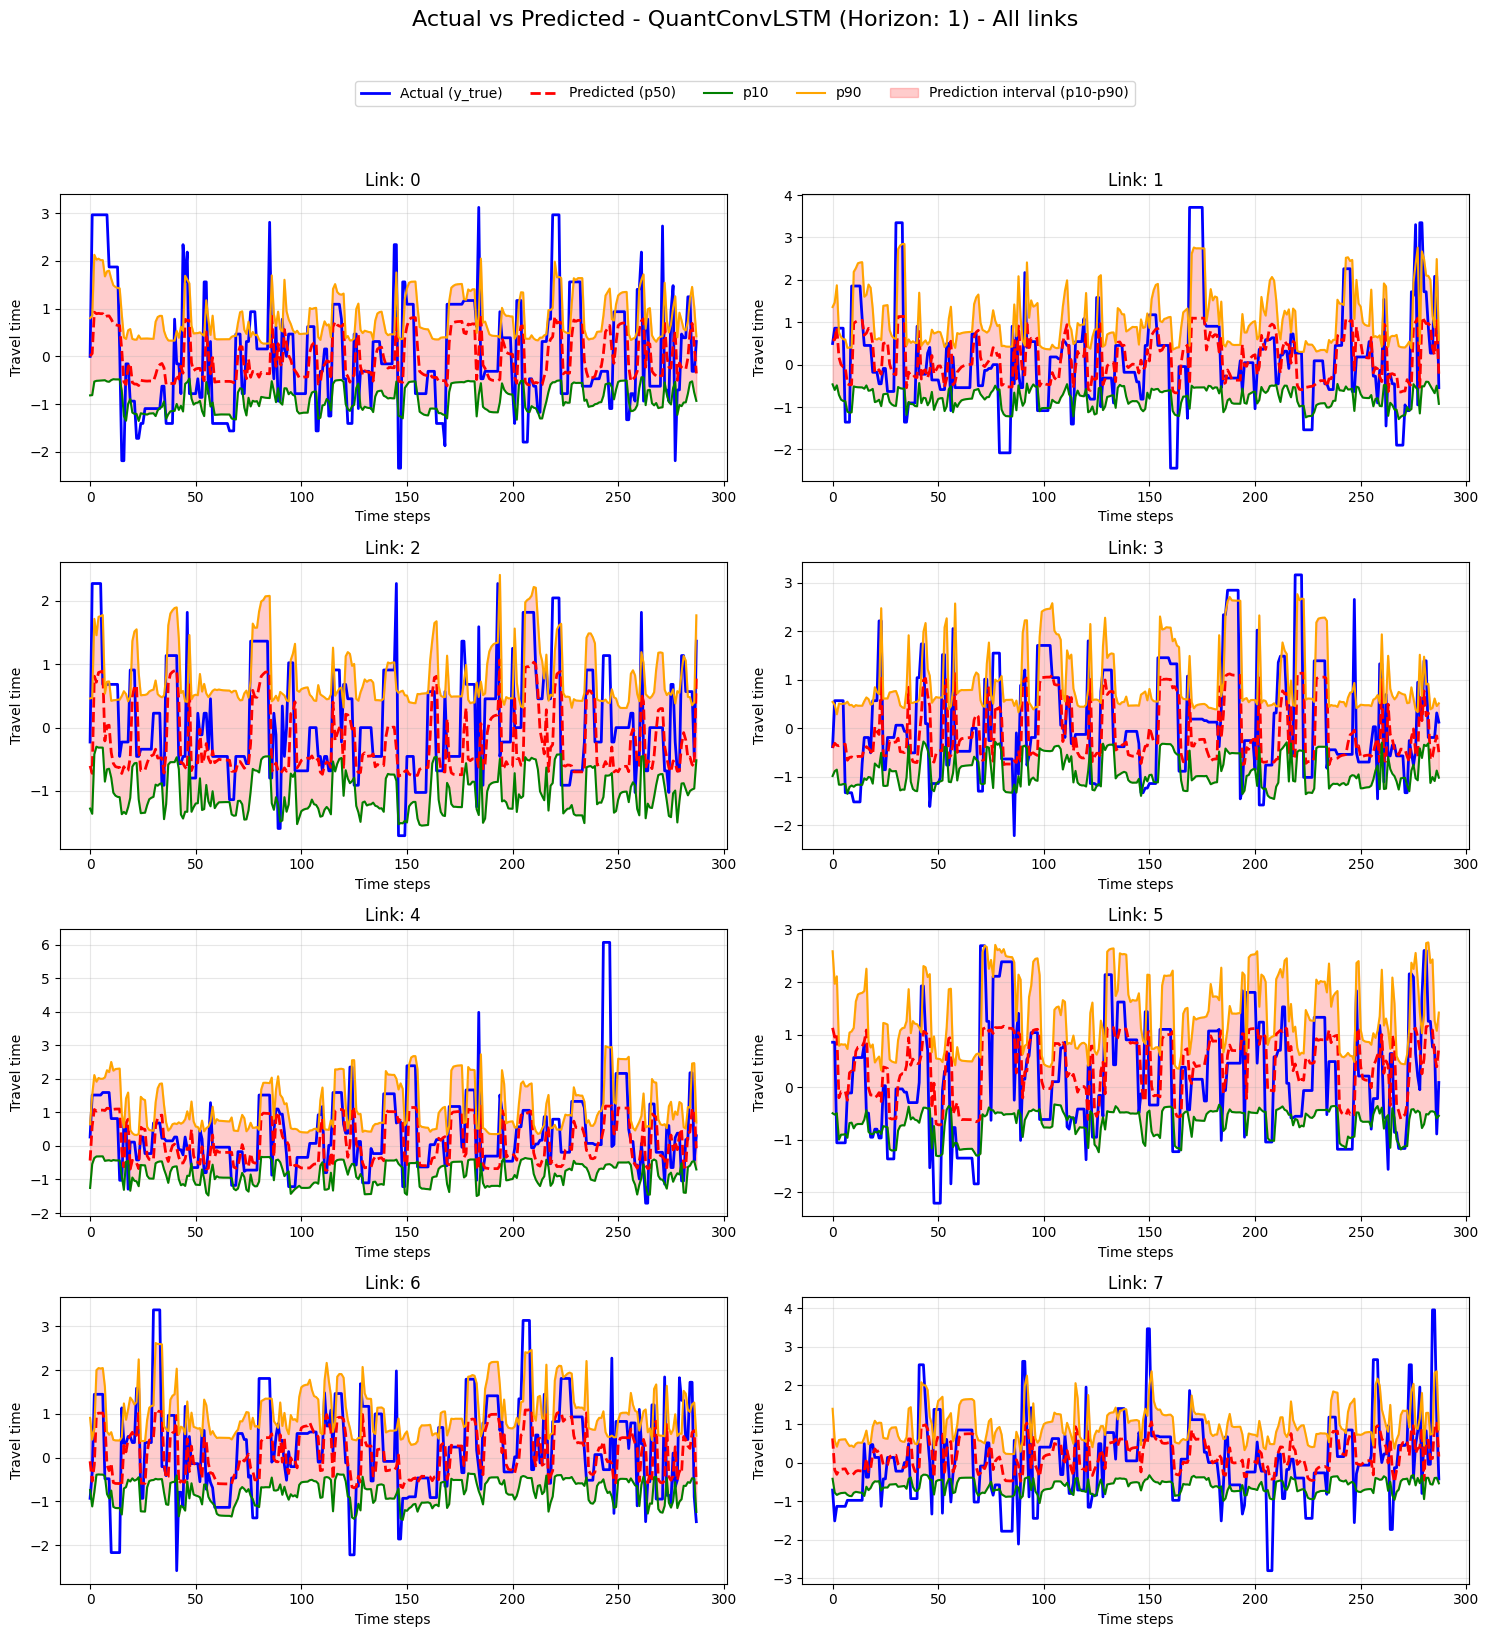

In [23]:
plot_test_predictions_quantiles_all_links(fixed_interval_model_trainer, horizon_idx=0, num_samples=NUM_SAMPLES_TO_PLOT)

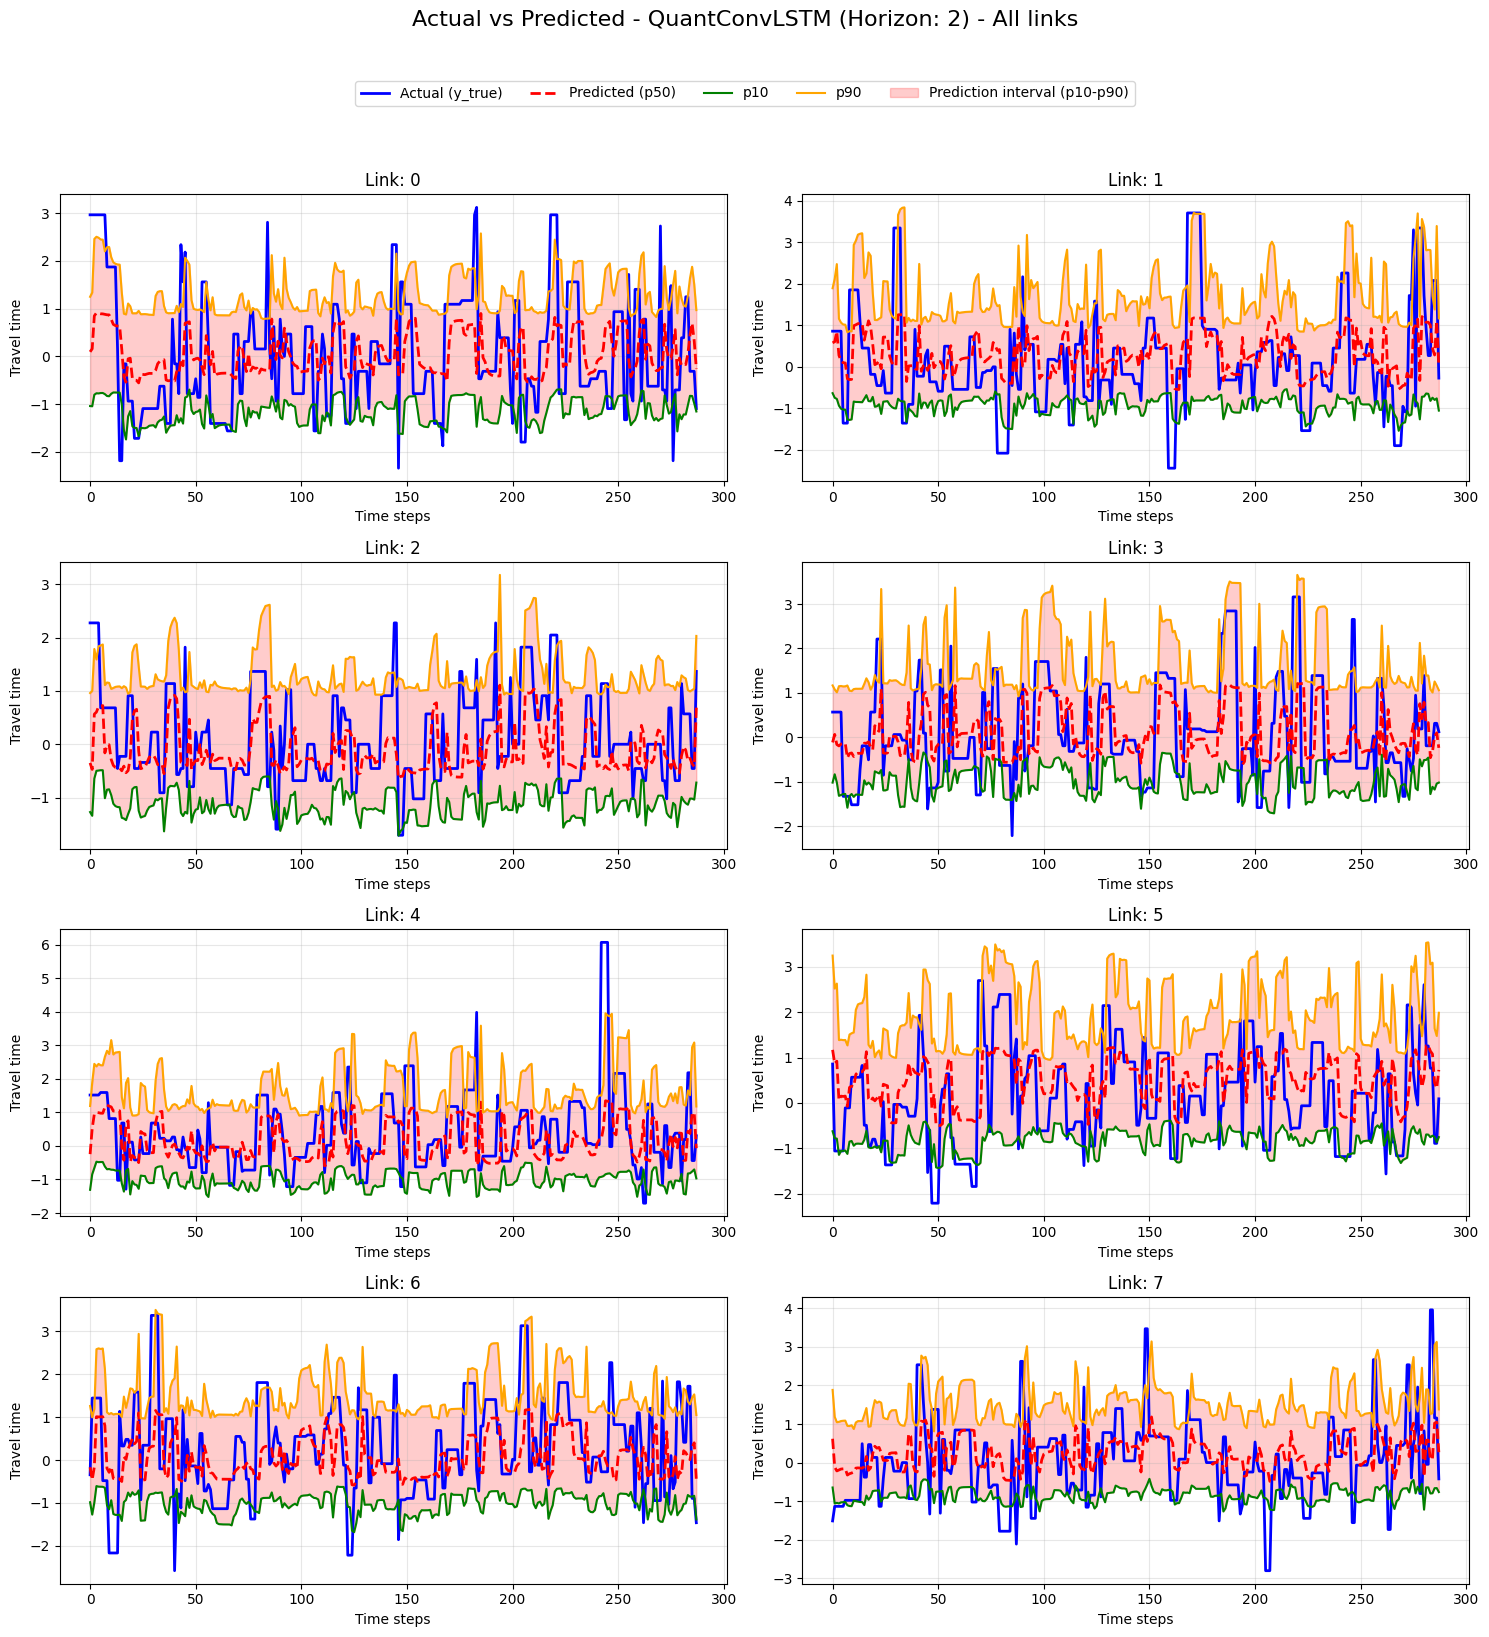

In [24]:
plot_test_predictions_quantiles_all_links(fixed_interval_model_trainer, horizon_idx=1, num_samples=NUM_SAMPLES_TO_PLOT)


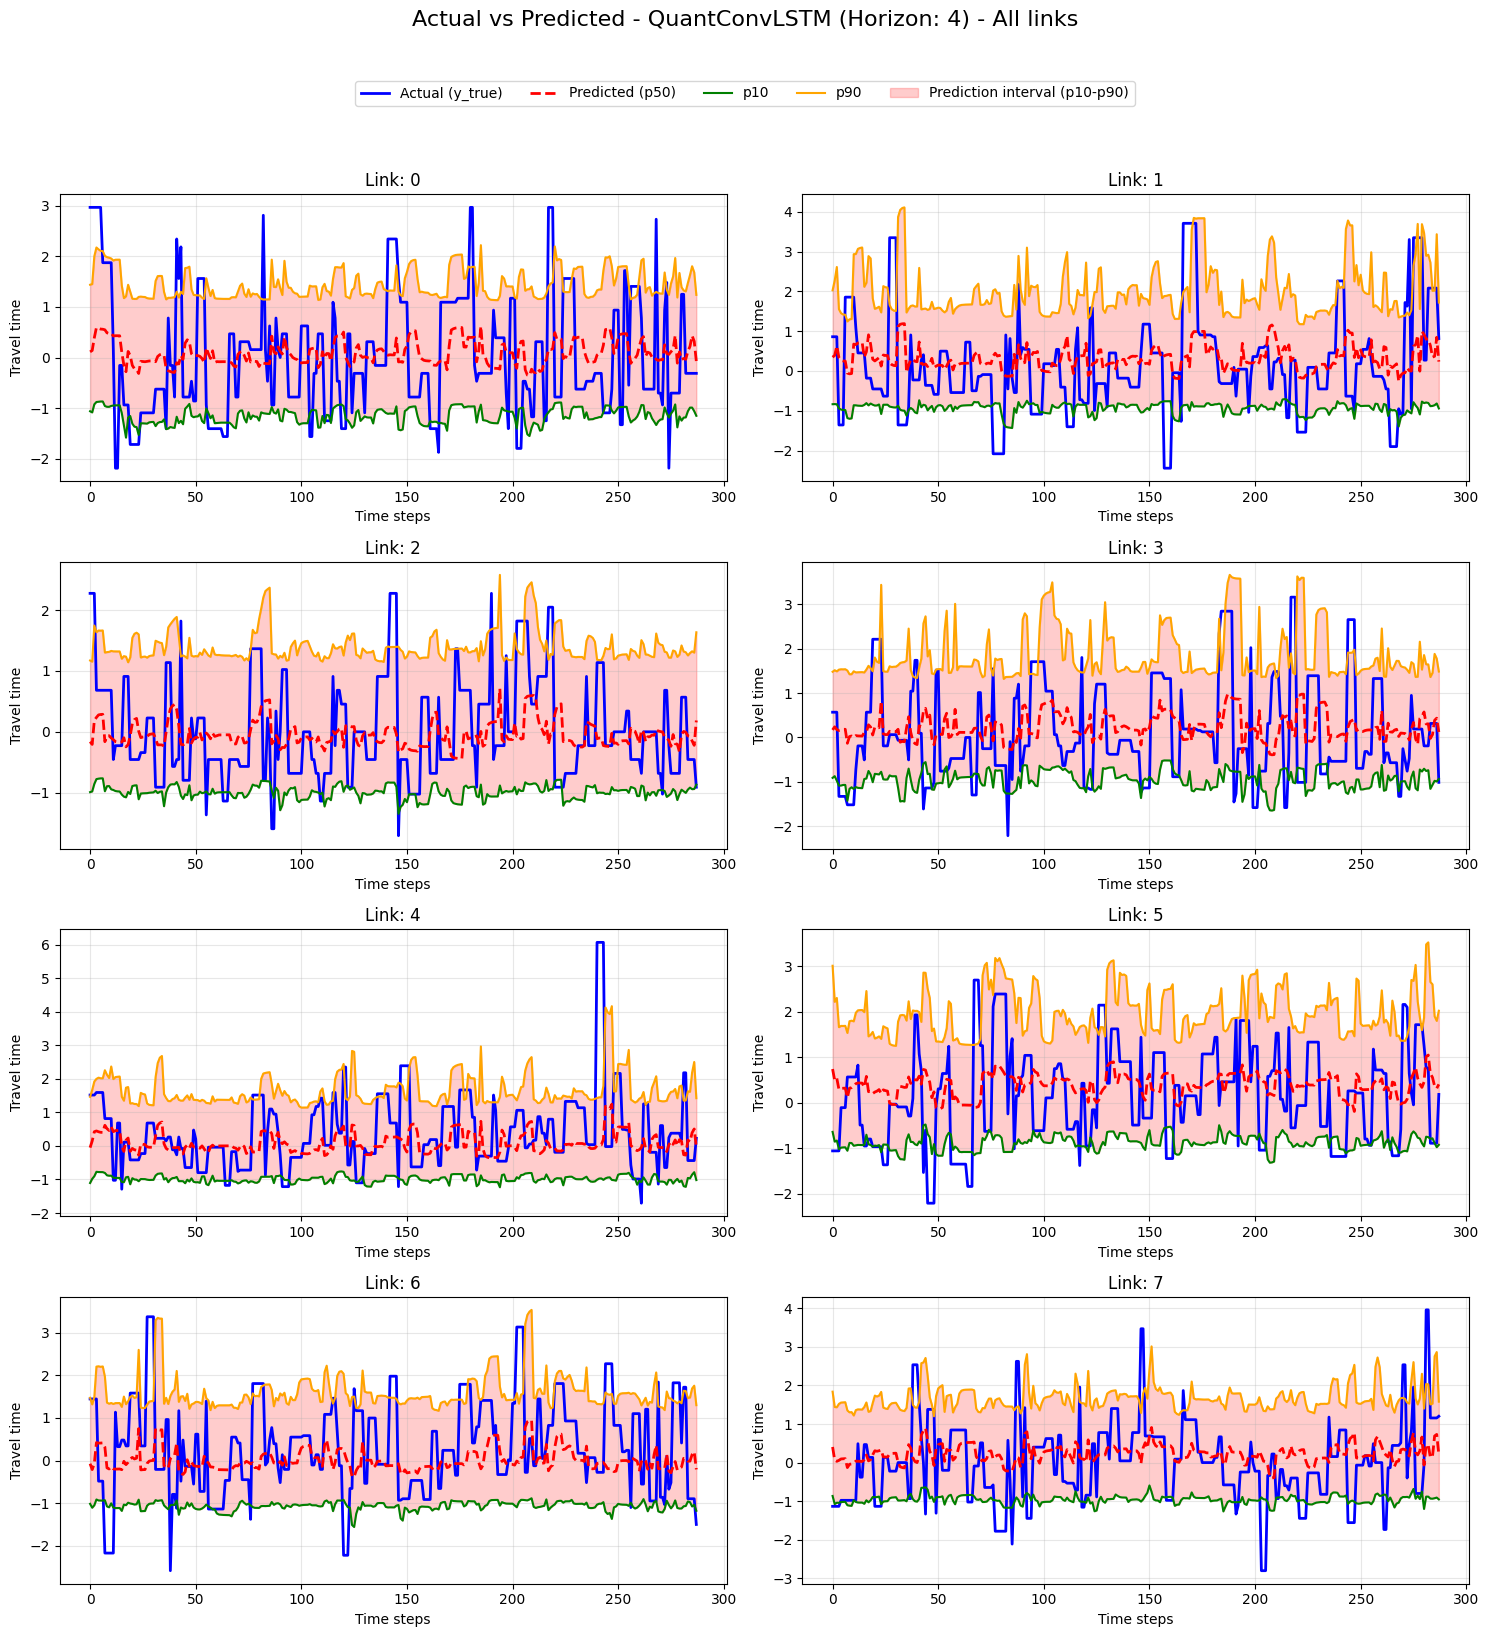

In [25]:
plot_test_predictions_quantiles_all_links(fixed_interval_model_trainer, horizon_idx=2, num_samples=NUM_SAMPLES_TO_PLOT)


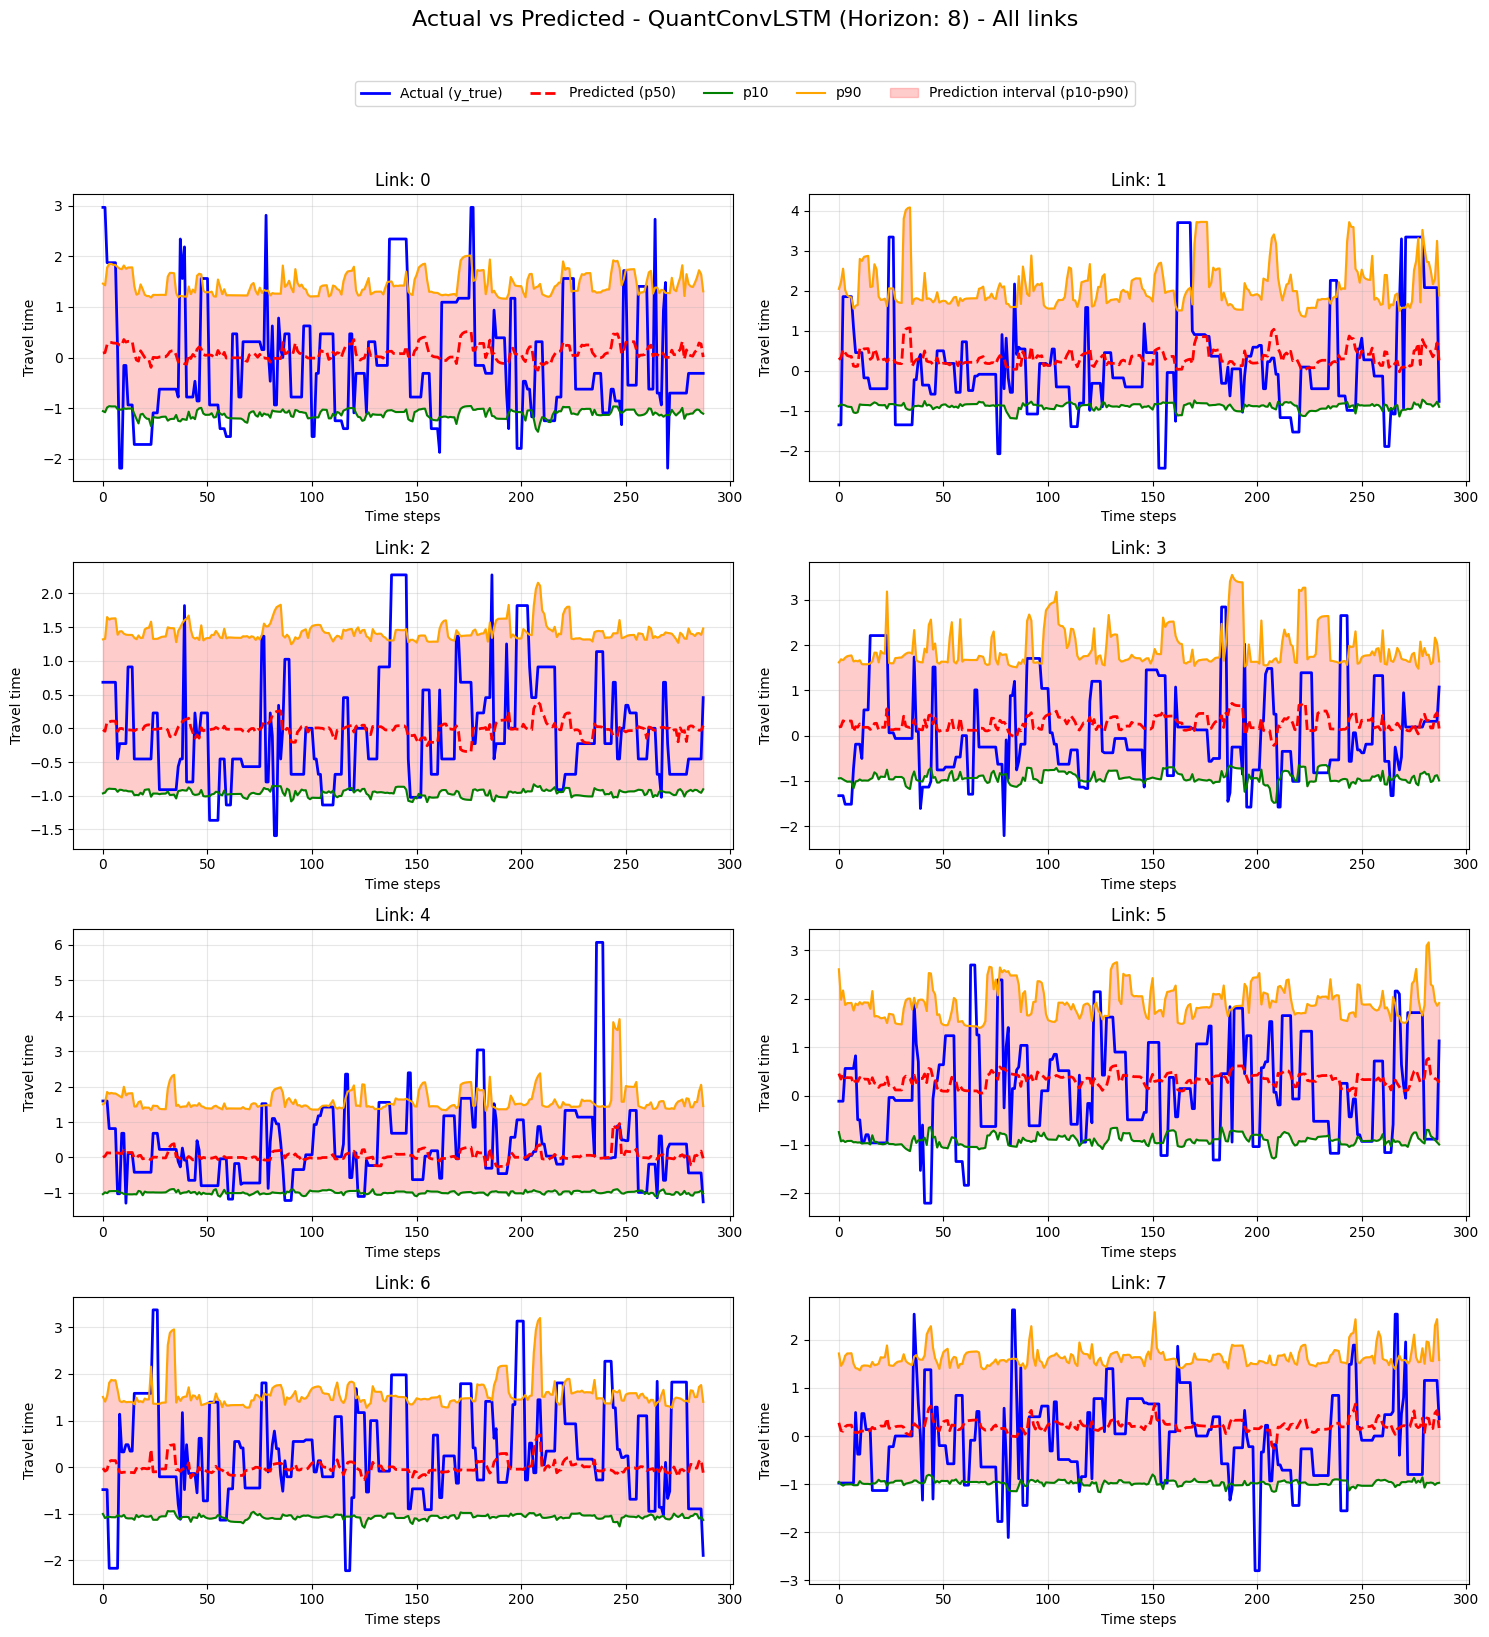

In [26]:
plot_test_predictions_quantiles_all_links(fixed_interval_model_trainer, horizon_idx=3, num_samples=NUM_SAMPLES_TO_PLOT)
